# Movie Data Analysis Report

**Name:** Makayla Brown   
**Date:** November 13, 2026  
**Course:** Data Analysis with Python

## Introduction

For this project, I selected the Vega Movies Dataset. I chose this dataset because I am interested in movies and wanted to learn more about movie ratings, production budgets, and box office earnings.

Each observation represents one movie. The dataset includes movie titles, production budgets, worldwide earnings, genres, and IMDb ratings.

### Research Question

Is there a relationship between a movie's production budget and its worldwide box office earnings?

### Hypothesis

I believe that movies with larger production budgets will generally earn more money worldwide.

In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

plt.style.use('ggplot')

print("Libraries imported successfully!")


Libraries imported successfully!


In [3]:
url = "https://raw.githubusercontent.com/vega/vega-datasets/main/data/movies.json"

df = pd.read_json(url)

df.head()

,Title,US Gross,Worldwide Gross,US DVD Sales,Production Budget,Release Date,MPAA Rating,Running Time min,Distributor,Source,Major Genre,Creative Type,Director,Rotten Tomatoes Rating,IMDB Rating,IMDB Votes
0,The Land Girls,146083.0,146083.0,NaN,8000000.0,Jun 12 1998,R,NaN,Gramercy,NaN,NaN,NaN,NaN,NaN,6.1,1071.0
1,"First Love, Last Rites",10876.0,10876.0,NaN,300000.0,Aug 07 1998,R,NaN,Strand,NaN,Drama,NaN,NaN,NaN,6.9,207.0
2,I Married a Strange Person,203134.0,203134.0,NaN,250000.0,Aug 28 1998,NaN,NaN,Lionsgate,NaN,Comedy,NaN,NaN,NaN,6.8,865.0
3,Let's Talk About Sex,373615.0,373615.0,NaN,300000.0,Sep 11 1998,NaN,NaN,Fine Line,NaN,Comedy,NaN,NaN,13.0,NaN,NaN
4,Slam,1009819.0,1087521.0,NaN,1000000.0,Oct 09 1998,R,NaN,Trimark,Original Screenplay,Drama,Contemporary Fiction,NaN,62.0,3.4,165.0


In [4]:
print("Dataset size:")
print(df.shape)

print("\nColumn information:")
df.info()

print("\nSummary statistics:")
df.describe()

Dataset size:
(3201, 16)

Column information:
<class 'pandas.DataFrame'>
RangeIndex: 3201 entries, 0 to 3200
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Title                   3200 non-null   object 
 1   US Gross                3194 non-null   float64
 2   Worldwide Gross         3194 non-null   float64
 3   US DVD Sales            564 non-null    float64
 4   Production Budget       3200 non-null   float64
 5   Release Date            3201 non-null   str    
 6   MPAA Rating             2596 non-null   str    
 7   Running Time min        1209 non-null   float64
 8   Distributor             2969 non-null   str    
 9   Source                  2836 non-null   str    
 10  Major Genre             2926 non-null   str    
 11  Creative Type           2755 non-null   str    
 12  Director                1870 non-null   str    
 13  Rotten Tomatoes Rating  2321 non-null   float64
 14  IMDB 

,US Gross,Worldwide Gross,US DVD Sales,Production Budget,Running Time min,Rotten Tomatoes Rating,IMDB Rating,IMDB Votes
count,3.194000e+03,3.194000e+03,5.640000e+02,3.200000e+03,1209.000000,2321.000000,2988.000000,2988.000000
mean,4.400209e+07,8.534340e+07,3.490155e+07,3.106917e+07,110.193548,54.336924,6.283467,29908.644578
std,6.255531e+07,1.499473e+08,4.589512e+07,3.558591e+07,20.171014,28.076593,1.252290,44937.582335
min,0.000000e+00,0.000000e+00,6.184540e+05,2.180000e+02,46.000000,1.000000,1.400000,18.000000
25%,5.493221e+06,8.031285e+06,9.906211e+06,6.575000e+06,95.000000,30.000000,5.600000,4828.500000
50%,2.201947e+07,3.116893e+07,2.033156e+07,2.000000e+07,107.000000,55.000000,6.400000,15106.000000
75%,5.609176e+07,9.728380e+07,3.779422e+07,4.200000e+07,121.000000,80.000000,7.200000,35810.500000
max,7.601676e+08,2.767891e+09,3.525821e+08,3.000000e+08,222.000000,100.000000,9.200000,519541.000000


In [5]:

numeric_columns = [
    'Production Budget',
    'Worldwide Gross',
    'IMDB Rating',
    'IMDB Votes'
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors='coerce')

clean_df = df.dropna(
    subset=[
        'Production Budget',
        'Worldwide Gross',
        'IMDB Rating',
        'Major Genre'
    ]
).copy()

clean_df = clean_df[
    (clean_df['Production Budget'] > 0) &
    (clean_df['Worldwide Gross'] > 0) &
    (clean_df['IMDB Rating'] > 0) &
    (clean_df['IMDB Rating'] <= 10)
]

print("Movies remaining:", len(clean_df))


Movies remaining: 2728



## Part 2: Explore the Data with Visualizations

### Histogram: Distribution of Movie Ratings

This histogram shows how IMDb ratings are distributed among the movies in the dataset. It helps identify the most common movie ratings and shows whether ratings are concentrated in a particular range.


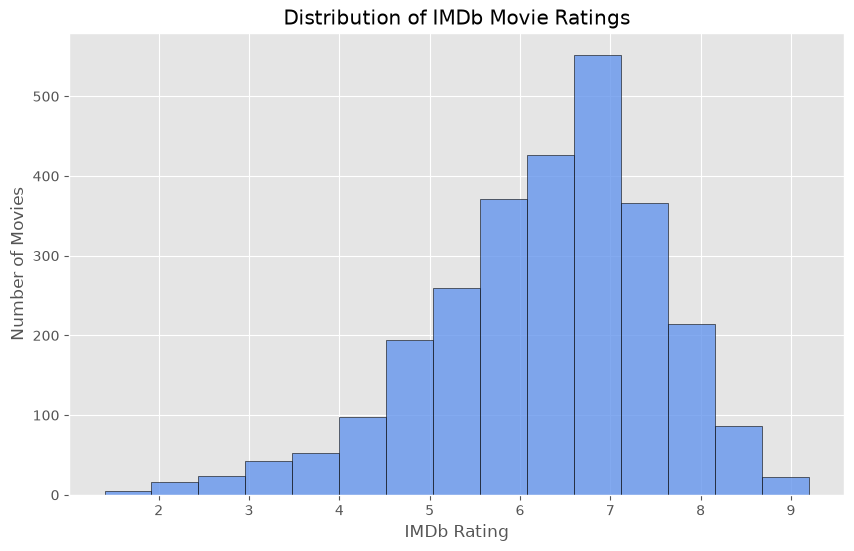

In [6]:

plt.figure(figsize=(10, 6))

plt.hist(
    clean_df['IMDB Rating'],
    bins=15,
    color='cornflowerblue',
    edgecolor='black',
    alpha=0.8
)

plt.title('Distribution of IMDb Movie Ratings')
plt.xlabel('IMDb Rating')
plt.ylabel('Number of Movies')

plt.show()



### Histogram Observations

The histogram shows how movie ratings are spread across the dataset. The bars help identify which rating ranges contain the most movies. The number of bins affects how detailed the distribution appears. More bins show smaller rating ranges, while fewer bins create a simpler overview.



### Histogram Observations

The histogram shows that most movies have IMDb ratings between 5 and 8. The highest concentration of movies appears around ratings of 6 to 7. There are fewer movies with very low or very high ratings. Using 15 bins helps show the distribution in detail.


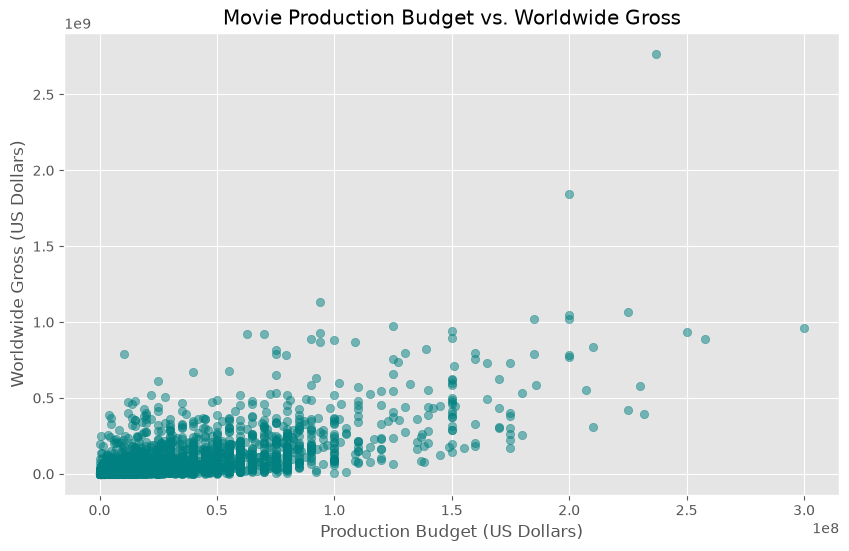

In [7]:

plt.figure(figsize=(10, 6))

plt.scatter(
    clean_df['Production Budget'],
    clean_df['Worldwide Gross'],
    color='teal',
    alpha=0.5,
    marker='o'
)

plt.title('Movie Production Budget vs. Worldwide Gross')
plt.xlabel('Production Budget (US Dollars)')
plt.ylabel('Worldwide Gross (US Dollars)')

plt.show()



### Scatter Plot Observations

The scatter plot compares movie production budgets with worldwide box office earnings. Each dot represents one movie. The graph helps show whether movies with larger production budgets tend to earn more money. It also shows that movie earnings can vary even when production budgets are similar.




## Boxplot: Comparing Movie Ratings by Genre

This boxplot compares IMDb movie ratings across different movie genres. It helps identify differences in median ratings, the spread of ratings, and unusual values among the genres.


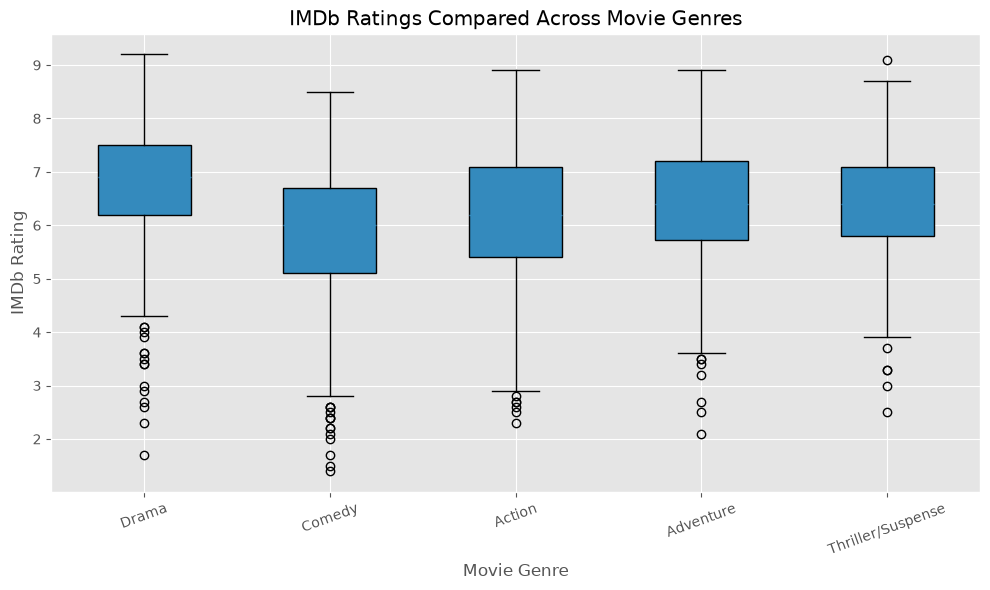

In [8]:

# Find the five most common movie genres
top_genres = (
    clean_df['Major Genre']
    .value_counts()
    .head(5)
    .index
)

# Organize ratings by genre
box_data = [
    clean_df.loc[
        clean_df['Major Genre'] == genre,
        'IMDB Rating'
    ].dropna()
    for genre in top_genres
]

# Create the boxplot
plt.figure(figsize=(10, 6))

plt.boxplot(
    box_data,
    tick_labels=top_genres,
    patch_artist=True
)

plt.title('IMDb Ratings Compared Across Movie Genres')
plt.xlabel('Movie Genre')
plt.ylabel('IMDb Rating')

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()



### Boxplot Observations

The boxplot compares movie ratings across five different genres. The lines inside the boxes represent the median ratings. The size of each box shows how spread out the ratings are. The individual points outside the boxes represent unusual values. This visualization helps compare how movie ratings differ between genres.


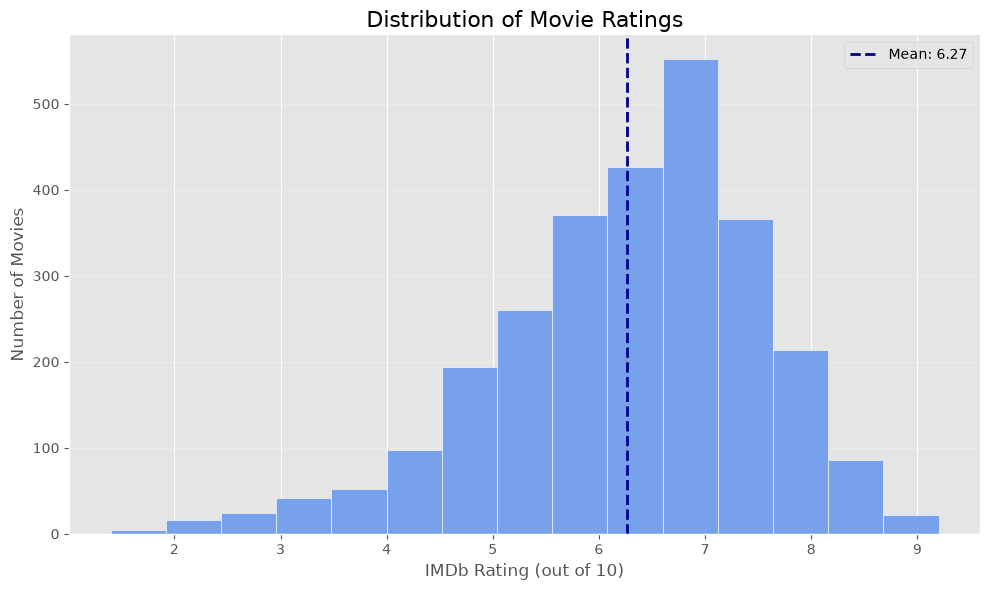

In [10]:

ratings = clean_df['IMDB Rating']

fig, ax = plt.subplots(figsize=(10, 6))

ax.hist(
    ratings,
    bins=15,
    color='cornflowerblue',
    edgecolor='white',
    alpha=0.85
)

ax.axvline(
    ratings.mean(),
    color='darkblue',
    linestyle='--',
    linewidth=2,
    label=f'Mean: {ratings.mean():.2f}'
)

ax.set_title('Distribution of Movie Ratings', fontsize=16)
ax.set_xlabel('IMDb Rating (out of 10)')
ax.set_ylabel('Number of Movies')

ax.legend()
ax.grid(axis='y', alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()


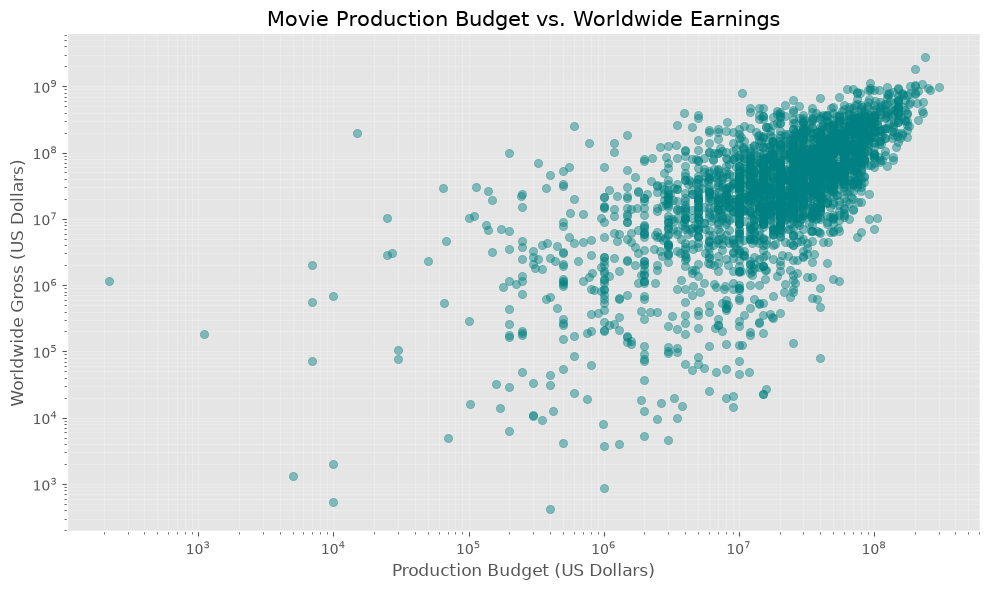

In [11]:

fig, ax = plt.subplots(figsize=(10, 6))

ax.scatter(
    clean_df['Production Budget'],
    clean_df['Worldwide Gross'],
    color='teal',
    alpha=0.45,
    s=35
)

ax.set_xscale('log')
ax.set_yscale('log')

ax.set_title(
    'Movie Production Budget vs. Worldwide Earnings',
    fontsize=15
)

ax.set_xlabel('Production Budget (US Dollars)')
ax.set_ylabel('Worldwide Gross (US Dollars)')

ax.grid(True, which='both', alpha=0.25)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()


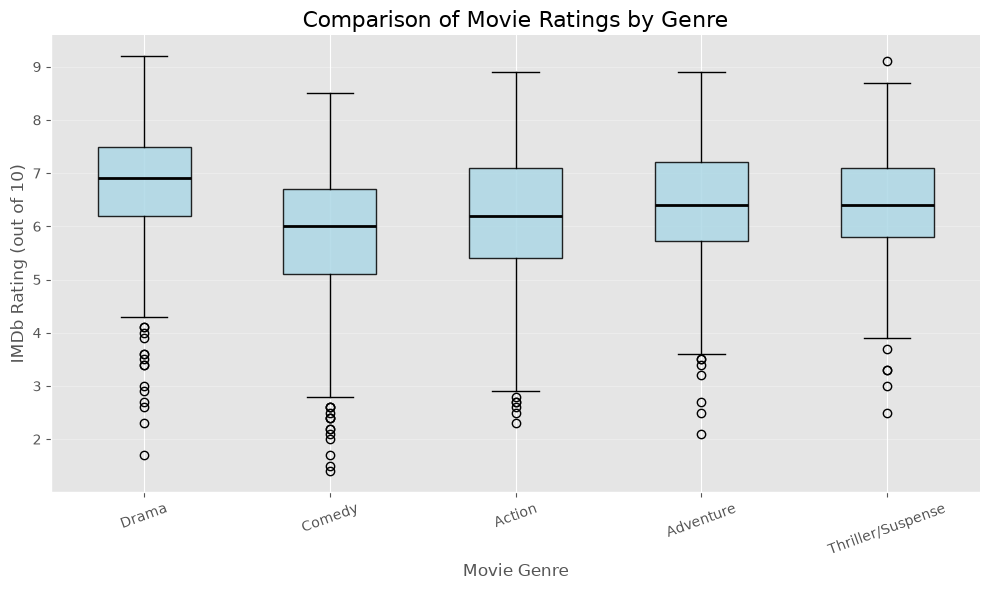

In [13]:


fig, ax = plt.subplots(figsize=(10, 6))

bp = ax.boxplot(
    box_data,
    tick_labels=top_genres,
    patch_artist=True,
    medianprops=dict(color='black', linewidth=2)
)

for box in bp['boxes']:
    box.set_facecolor('lightblue')
    box.set_alpha(0.85)

ax.set_title('Comparison of Movie Ratings by Genre', fontsize=16)
ax.set_xlabel('Movie Genre')
ax.set_ylabel('IMDb Rating (out of 10)')

ax.grid(axis='y', alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()



## Visualization Design Decisions

I made several changes to improve my visualizations.

1. I used consistent colors to make the graphs look organized.
2. I increased the figure sizes to make the graphs easier to read.
3. I added descriptive titles and labels to explain what each graph represents.
4. I used transparency in the scatter plot to make overlapping points easier to see.
5. I added a mean reference line to the histogram.
6. I adjusted gridlines and removed unnecessary borders to make the graphs look cleaner.
7. I used logarithmic scales in the scatter plot because movie budgets and earnings have a wide range of values.

These design choices make my visualizations easier to understand and help communicate the information more effectively.



# Part 4: Statistical Analysis

## OLS Regression: Production Budget and Worldwide Gross

I selected Option B because I want to investigate the relationship between two numerical variables.

My independent variable (X) is the production budget.

My dependent variable (Y) is worldwide gross earnings.

I will use an Ordinary Least Squares (OLS) regression model to investigate whether production budgets are related to worldwide movie earnings.



# Part 4: Statistical Analysis

## OLS Regression: Production Budget and Worldwide Gross

I selected Option B because I want to investigate the relationship between two numerical variables.

My independent variable (X) is the production budget.

My dependent variable (Y) is worldwide gross earnings.

I will use an Ordinary Least Squares (OLS) regression model to investigate whether production budgets are related to worldwide movie earnings.



# Part 4: Statistical Analysis

## OLS Regression: Production Budget and Worldwide Gross

I selected Option B because I want to investigate the relationship between two numerical variables.

My independent variable (X) is the production budget.

My dependent variable (Y) is worldwide gross earnings.

I will use an Ordinary Least Squares (OLS) regression model to investigate whether production budgets are related to worldwide movie earnings.



# Part 4: Statistical Analysis

## OLS Regression: Production Budget and Worldwide Gross

I selected Option B because I want to investigate the relationship between two numerical variables.

My independent variable (X) is the production budget.

My dependent variable (Y) is worldwide gross earnings.

I will use an Ordinary Least Squares (OLS) regression model to investigate whether production budgets are related to worldwide movie earnings.


In [14]:

# Create logarithmic variables
clean_df['Log_Budget'] = np.log10(
    clean_df['Production Budget']
)

clean_df['Log_Gross'] = np.log10(
    clean_df['Worldwide Gross']
)

# Build the regression model
model = smf.ols(
    'Log_Gross ~ Log_Budget',
    data=clean_df
).fit()

# Display the results
print(model.summary())


                            OLS Regression Results                            
Dep. Variable:              Log_Gross   R-squared:                       0.418
Model:                            OLS   Adj. R-squared:                  0.418
Method:                 Least Squares   F-statistic:                     1958.
Date:                Fri, 13 Nov 2026   Prob (F-statistic):               0.00
Time:                        10:59:34   Log-Likelihood:                -2848.8
No. Observations:                2728   AIC:                             5702.
Df Residuals:                    2726   BIC:                             5713.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.9603      0.147      6.542      0.0

In [15]:

correlation = clean_df['Production Budget'].corr(
    clean_df['Worldwide Gross']
)

print("Number of movies:", len(clean_df))

print("Correlation:", round(correlation, 3))

print("R-squared:", round(model.rsquared, 3))

print(
    "Regression coefficient:",
    round(model.params['Log_Budget'], 3)
)

print(
    "P-value:",
    model.pvalues['Log_Budget']
)

if model.pvalues['Log_Budget'] < 0.05:
    print("The relationship is statistically significant.")
else:
    print("The relationship is not statistically significant.")


Number of movies: 2728
Correlation: 0.666
R-squared: 0.418
Regression coefficient: 0.895
P-value: 0.0
The relationship is statistically significant.




## Interpretation of Statistical Results

The OLS regression analysis investigates whether production budgets are related to worldwide movie earnings.

The regression coefficient explains the direction and size of the relationship. Since I used logarithms, the coefficient estimates how worldwide earnings change when the production budget increases by 1%.

The p-value helps determine whether the relationship is statistically significant. A p-value below 0.05 suggests that there is a statistically significant relationship.

The R-squared value explains how much variation in worldwide movie earnings can be explained by production budgets.

One limitation of this analysis is that movie earnings depend on more than production budgets. Marketing, movie genres, release dates, and audience interest can also influence earnings. This analysis shows an association, not proof that a larger budget causes higher earnings.



In [17]:

print("FINAL PROJECT RESULTS")
print("----------------------")

print("Movies analyzed:", len(clean_df))

print(
    "Average IMDb rating:",
    round(clean_df['IMDB Rating'].mean(), 2)
)

print(
    "Average production budget:",
    round(clean_df['Production Budget'].mean(), 2)
)

print(
    "Average worldwide gross:",
    round(clean_df['Worldwide Gross'].mean(), 2)
)

print(
    "Correlation:",
    round(correlation, 3)
)

print(
    "R-squared:",
    round(model.rsquared, 3)
)

print(
    "P-value:",
    round(model.pvalues['Log_Budget'], 6)
)


FINAL PROJECT RESULTS
----------------------
Movies analyzed: 2728
Average IMDb rating: 6.27
Average production budget: 33833183.39
Average worldwide gross: 92999270.01
Correlation: 0.666
R-squared: 0.418
P-value: 0.0



# Part 5: Conclusion and Reflection

This project helped me understand how Python can be used to organize, analyze, and visualize data.

My research question investigated whether movie production budgets are related to worldwide box office earnings.

The histogram helped me understand the distribution of movie ratings. The scatter plot helped me examine the relationship between production budgets and worldwide earnings. The boxplot allowed me to compare movie ratings across different genres.

My original hypothesis was that movies with larger production budgets would generally earn more money worldwide. Based on my statistical analysis, I found that [explain whether your results supported your hypothesis].

The scatter plot was the most effective visualization because it allowed me to compare two numerical variables and look for patterns.

The statistical analysis provided additional information through the correlation, regression coefficient, p-value, and R-squared value.

One limitation of this dataset is that it does not explain every factor that contributes to a movie's success. Marketing, release dates, competition, and audience preferences can also affect worldwide earnings.

In the future, I would like to include additional information about marketing expenses and audience demographics to improve my investigation.

Overall, this project helped me improve my understanding of pandas, matplotlib, data visualization, and statistical analysis.
